## 1. Load the pretrained detector

In [1]:
import pathlib, torch, pandas as pd, matplotlib.pyplot as plt, matplotlib.patches as mpatches
from PIL import Image
from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection

MODEL_ID = 'IDEA-Research/grounding-dino-tiny'
processor = AutoProcessor.from_pretrained(MODEL_ID, max_pixels=896*896)
model = AutoModelForZeroShotObjectDetection.from_pretrained(MODEL_ID)
model.eval()
print(f'model      : {MODEL_ID}')
print(f'params     : {sum(p.numel() for p in model.parameters()):,}')
print(f'task       : zero-shot object detection with text prompts')

model      : IDEA-Research/grounding-dino-tiny
params     : 172,249,090
task       : zero-shot object detection with text prompts


## 2. Prompts and image

Grounding-DINO takes an image + a text prompt string (phrases separated by `. `). It returns bounding boxes whose semantic content matches the phrases.

In [2]:
PROMPTS = ['pleural effusion', 'cardiomegaly', 'nodule', 'mass',
           'pneumothorax', 'consolidation', 'atelectasis']
text = '. '.join(PROMPTS) + '.'
print('text prompt sent to Grounding-DINO:')
print(f'  "{text}"')

ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
IMG_DIR = ROOT / 'datasets' / 'iu_xray' / 'images'
img_path = next(iter(sorted(IMG_DIR.glob('*.png'))))
image = Image.open(img_path).convert('RGB')
W, H = image.size
print(f'\nimage      : {img_path.name}')
print(f'resolution : {W} x {H}')

text prompt sent to Grounding-DINO:
  "pleural effusion. cardiomegaly. nodule. mass. pneumothorax. consolidation. atelectasis."

image      : 10_IM-0002-2001.dcm.png
resolution : 2496 x 2048


## 3. Run inference (~5–15 s on CPU)

In [3]:
inputs = processor(images=image, text=text, return_tensors='pt')
with torch.no_grad():
    outputs = model(**inputs)

try:
    results = processor.post_process_grounded_object_detection(
        outputs, inputs.input_ids,
        threshold=0.30, text_threshold=0.25, target_sizes=[(H, W)])[0]
except TypeError:
    results = processor.post_process_grounded_object_detection(
        outputs, inputs.input_ids,
        box_threshold=0.30, text_threshold=0.25, target_sizes=[(H, W)])[0]

detections = []
for score, label, box in zip(results['scores'], results['labels'], results['boxes']):
    x1, y1, x2, y2 = (float(v) for v in box.tolist())
    detections.append({'label': str(label), 'score': float(score),
                       'x1': round(x1, 1), 'y1': round(y1, 1),
                       'x2': round(x2, 1), 'y2': round(y2, 1)})
pd.DataFrame(detections)

D:\STUDY\DL Lab\Project\VisionGuard-Medical\.venv\Lib\site-packages\transformers\models\grounding_dino\processing_grounding_dino.py:93: FutureWarning: The key `labels` is will return integer ids in `GroundingDinoProcessor.post_process_grounded_object_detection` output since v4.51.0. Use `text_labels` instead to retrieve string object names.
  warnings.warn(self.message, FutureWarning)


,label,score,x1,y1,x2,y2
0,atelectasis,0.320960,19.4,16.9,2476.6,2027.8
1,pleural effusion,0.354389,537.0,183.7,1317.6,1571.8
2,consolidation,0.301660,16.7,13.8,2478.1,2031.9


## 4. Draw the boxes on the X-ray

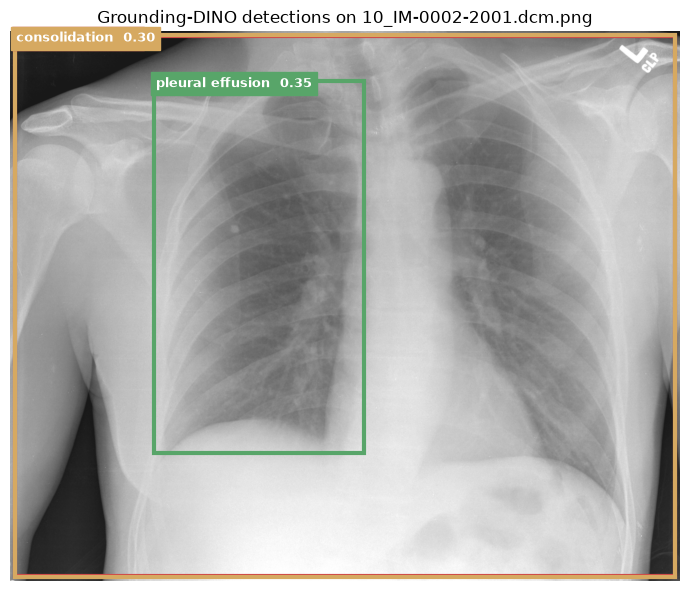

In [4]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(image, cmap='gray')
ax.axis('off')
ax.set_title(f'Grounding-DINO detections on {img_path.name}')

palette = ['#CF4647', '#58A569', '#D6A961', '#5B8FB9', '#B06AB3', '#E07B39', '#6BB6E3']
for i, d in enumerate(detections):
    color = palette[i % len(palette)]
    w, h = d['x2'] - d['x1'], d['y2'] - d['y1']
    ax.add_patch(mpatches.Rectangle((d['x1'], d['y1']), w, h,
                                    linewidth=3, edgecolor=color, facecolor='none'))
    ax.text(d['x1'] + 6, d['y1'] + 24,
            f"{d['label']}  {d['score']:.2f}",
            color='white', backgroundcolor=color, fontsize=9, weight='bold')
if not detections:
    ax.text(W/2, H/2, 'no detections above threshold',
            ha='center', va='center', color='red', fontsize=14)
plt.tight_layout(); plt.show()